# IR 01d — bin average + balance

This worked example starts from the **native acquisition checkpoint**, not the prefiltered baseline. Inspect, hypothesize, implement, and verify before fitting the unchanged classifier. No synthetic corruptions are added to make a strategy appear successful.

All options exclude every observation of held-out molecules and copy validation/test byte-for-byte. Only training is changed. Model features always end as the same finite **500-point grid with 12 binary targets**. Audit columns never become features. This strategy combines several changes; a performance difference cannot be attributed to just one of them.

In [1]:
from pathlib import Path
import sys
for parent in [Path.cwd(), *Path.cwd().parents]:
    candidates = [parent, parent / '02_ir_functional_groups']
    module = next((p for p in candidates if (p / 'ir_carpentry.py').is_file()), None)
    if module is not None:
        sys.path.insert(0, str(module)); sys.path.insert(0, str(module / 'examples')); break
else:
    raise FileNotFoundError('Keep the examples folder inside the IR module.')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from ir_carpentry import (LABELS, load_native, ensure_frozen_evaluation, training_pool,
                         prepare_training, save_carpentry, validate_frozen_evaluation)
from ir_example_support import examine_native, cleanse_training, validate_tables

MODULE = module.resolve()
OUTPUT_DIR = MODULE / 'examples/outputs/01d_resampling_and_balancing'
SIGNAL_POLICY = 'convert_transmittance'
BOUNDS_POLICY = 'zero_pad'
RESAMPLING = 'bin_average_then_upsample'
CLEANSING = 'capped_rare_oversampling'
source, source_file = load_native(MODULE)
holdouts, grid, contract = ensure_frozen_evaluation(MODULE, source)
pool, excluded = training_pool(source, holdouts)
print(f'Native candidates: {len(pool):,}; held-out observations excluded: {excluded:,}')
print('Frozen grid/labels:', len(grid), len(LABELS), 'Frozen test hash:', contract['sha256']['test'])

[18:17:57] WARNING: not removing hydrogen atom without neighbors
[18:17:57] WARNING: not removing hydrogen atom without neighbors
[18:17:57] WARNING: not removing hydrogen atom without neighbors


[18:17:57] WARNING: not removing hydrogen atom without neighbors


Native candidates: 9,027; held-out observations excluded: 1,974
Frozen grid/labels: 500 12 Frozen test hash: fde8bb1a7d770dc498299a09141b0ba9108b3366b06e4c34697506f9af4cc2a1


## Examine — prompt to your coding assistant

> Inspect native TRAINING candidates for categorical outliers, missing/nonbinary labels, invalid/duplicate molecular identities, NaN/Inf inside arrays, unequal lengths, reversed/repeated coordinates, coverage and signal-unit differences. Count absorbance, transmittance and unsupported signals. Inspect valid ranges without guessing percent from amplitude. Show descriptive quantiles, coverage and category frequencies. Distinguish statistical anomalies from legitimate rare chemistry. Do not tune any rule on held-out spectra or test scores.

Native training-candidate units (not the held-out reference):


rows
xunits      yunits             
1/CM        ABSORBANCE     4533
            REFLECTANCE       1
            TRANSMITTANCE  2607
MICROMETERS TRANSMITTANCE  1886

,SMILES,CAS_NO,Vinylic,Arene,Alcohol,Ether,Amine,Nitrile,Aldehyde,Ketone,CarboxylAcid,Ester,Amide,AcidChloride
missing_cells,0,564,0,0,0,0,0,0,0,0,0,0,0,0


,positive,invalid_or_missing
Vinylic,1226,0
Arene,5404,0
Alcohol,2169,0
Ether,2483,0
Amine,1665,0
Nitrile,358,0
Aldehyde,172,0
Ketone,771,0
CarboxylAcid,621,0
Ester,1124,0


[18:18:00] WARNING: not removing hydrogen atom without neighbors
[18:18:00] WARNING: not removing hydrogen atom without neighbors
[18:18:00] WARNING: not removing hydrogen atom without neighbors


[18:18:00] WARNING: not removing hydrogen atom without neighbors


Invalid SMILES / duplicate canonical molecules: 0 50


,rows
status,
valid_explicit_units,8457
transmittance_outside_explicit_unit_range,569
unsupported_signal_units,1


,native_points,low,high,signal_min,signal_max,coverage
0.00,825.00,92.08800,626.291727,0.000000,0.00300,0.00800
0.01,825.00,246.50372,3780.000000,0.000000,0.00900,0.94112
0.50,1790.00,550.00000,3999.500000,0.000000,0.88867,1.00000
0.99,3915.74,677.69760,5017.561465,0.122679,3.00000,1.00000
1.00,7152.00,1005.74200,10438.413361,0.312025,4.00000,1.00000


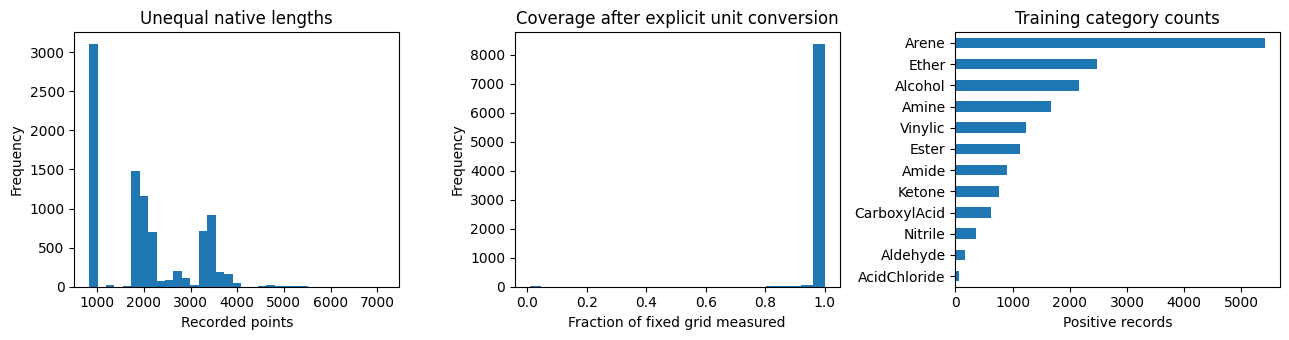

In [2]:
native_statistics = examine_native(pool, grid, OUTPUT_DIR)

## Carpentry — prompted hypothesis

> Hypothesis: a lower-resolution representation may reduce sensitivity to small spectral variations, and rare labels receive too few training presentations. Convert valid transmittance to absorbance, crop and permit explicitly documented zero padding with at least 80% measured coverage. Bin-average the measured region down to 250 points, then linearly upsample back onto the shared 500-point model grid. The audit shows the retained native spectra are denser than 500 points; this intentional two-stage experiment therefore demonstrates real downsampling AND upsampling. Upsampling restores dimensions, not lost experimental detail, and this can hurt performance. Normalize measured values before padding. Conservatively repeat rare-label training examples toward the lower-quartile positive count, capped at three presentations per original observation. Audit co-occurring labels and remember the model already uses class weights.

Added 609 presentations, not new molecules; cap three per original observation.
This changes co-occurring category frequencies and combines with the static model class weights.


events
action                         reason                                                    
kept                           cropped_and_interpolated                              4533
                               micrometers_to_wavenumber;transmittance_to_abso...    1538
                               transmittance_to_absorbance;cropped_and_interpo...     287
                               transmittance_to_absorbance;zero_padded               1596
rejected                       insufficient_measured_coverage                          21
                               invalid_identity                                       564
                               transmittance_outside_explicit_unit_range              487
                               unsupported_signal_units                                 1
repeated_training_presentation rare_AcidChloride                                      118
                               rare_Aldehyde                                          326
                               rare_Nitrile                                           165

After spectral preparation: 7,954; after additional cleansing: 8,563
Final resampling actions: {'downsampled_bin_average_to_250_then_upsampled_linear': 8563}
Padded training presentations: 3275


,before additional cleansing,after
Vinylic,1112,1184
Arene,4743,5131
Alcohol,1938,2000
Ether,2215,2381
Amine,1376,1396
Nitrile,324,491
Aldehyde,163,489
Ketone,719,728
CarboxylAcid,544,548
Ester,995,1031


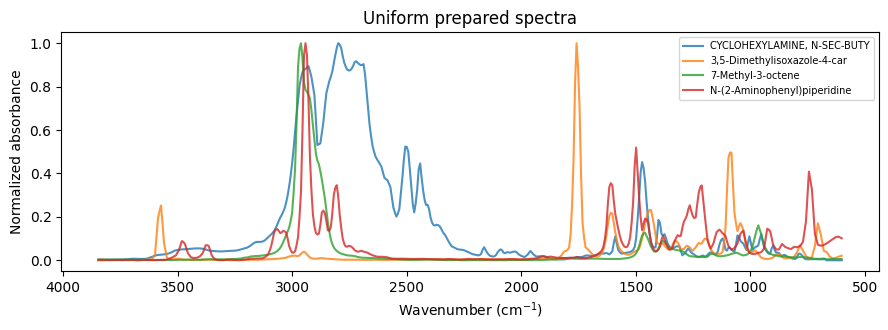

In [3]:
prepared, audit = prepare_training(pool, grid, SIGNAL_POLICY, BOUNDS_POLICY,
    minimum_coverage=.8, resampling=RESAMPLING)
before_rows = len(prepared)
before_counts = prepared[LABELS].sum()
train, additional_audit = cleanse_training(prepared, CLEANSING)
audit = pd.concat([audit, additional_audit], ignore_index=True)
display(audit.groupby(['action', 'reason']).size().rename('events').to_frame())
print(f'After spectral preparation: {before_rows:,}; after additional cleansing: {len(train):,}')
print('Final resampling actions:', train.resampling_action.value_counts().to_dict())
print('Padded training presentations:', int(train.padded_points.gt(0).sum()))
display(pd.DataFrame({'before additional cleansing': before_counts, 'after': train[LABELS].sum()}))
fig, ax = plt.subplots(figsize=(9, 3.4))
for _, row in train.head(4).iterrows():
    ax.plot(grid, row.IR, label=str(row.Name)[:27], alpha=.8)
ax.invert_xaxis(); ax.set(xlabel='Wavenumber (cm$^{-1}$)', ylabel='Normalized absorbance', title='Uniform prepared spectra')
ax.legend(fontsize=7); fig.tight_layout(); fig.savefig(OUTPUT_DIR / 'prepared_spectra.png', dpi=140); plt.show()

## Verify the uniform handoff — final prompted action

> Save and reload the prepared training file, labels, manifest and audit. Assert that every saved feature row has exactly the same 500 finite values on the frozen grid; targets are 12 binary columns in the fixed order. Report the model matrix shape, normalization range, positive category counts and duplicate presentations. Assert no held-out molecule is present in training and check exact validation/test file hashes. Do not start training until all checks pass.

In [4]:
choices = dict(example='01d', signal_policy=SIGNAL_POLICY, bounds_policy=BOUNDS_POLICY,
    resampling=RESAMPLING, minimum_coverage=.8, normalization='per_spectrum_minmax_absorbance',
    cleansing=CLEANSING, training_identity_guard=True)
manifest = save_carpentry(MODULE, OUTPUT_DIR, train, source_file, choices, audit, len(source))
tables = {name: pd.read_parquet(OUTPUT_DIR / f'IR_{name}.parquet') for name in ('train', 'validation', 'test')}
validate_tables(tables, grid)
validate_frozen_evaluation(MODULE, OUTPUT_DIR, grid)
features = np.vstack(tables['train'].IR).astype(np.float32)
assert features.shape == (len(tables['train']), 500)
assert features.min() >= -1e-6 and features.max() <= 1 + 1e-6
assert len(LABELS) == 12
print('PASS: saved/reloaded uniform matrix', features.shape, '; dtype', features.dtype)
print('PASS: 12 binary labels, fixed coordinate grid, no training/held-out overlap, unchanged evaluation hashes.')
print('Rows:', manifest['rows'])
print("Ready for static IR 02: CARPENTRY_DIR = Path('examples/outputs/01d_resampling_and_balancing')")

PASS: saved/reloaded uniform matrix (8563, 500) ; dtype float32
PASS: 12 binary labels, fixed coordinate grid, no training/held-out overlap, unchanged evaluation hashes.
Rows: {'input': 11001, 'train': 8563, 'validation': 975, 'test': 975}
Ready for static IR 02: CARPENTRY_DIR = Path('examples/outputs/01d_resampling_and_balancing')


## Evaluate honestly

The next step is the same IR 02 classifier, not a specially tuned model for this example. IR 03 assembles observed validation/test results, epoch counts and stopping reasons. These single-seed fits and bundled interventions do not establish a causal benefit for any individual step. The baseline may outperform a more elaborate strategy. Keep test scores for final reporting rather than choosing policies by them.